In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


# Qiskit Superposition 02
Various state can be expressed at the same time by creating superposition.
In terms of n bits binary number, we can easily make n states by operating Hadamard to all the qubits.  

What if we want to make n-1 states by n qubits?
That is not so simple, so my goal is to make an algorithm which enables us to make any kinds of superposition.

In [2]:
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit_backend_config import IBMQ, execute, Aer
from qiskit.visualization import plot_histogram
import math

## 2 qubits superposition

{'01': 303, '00': 358, '11': 363}


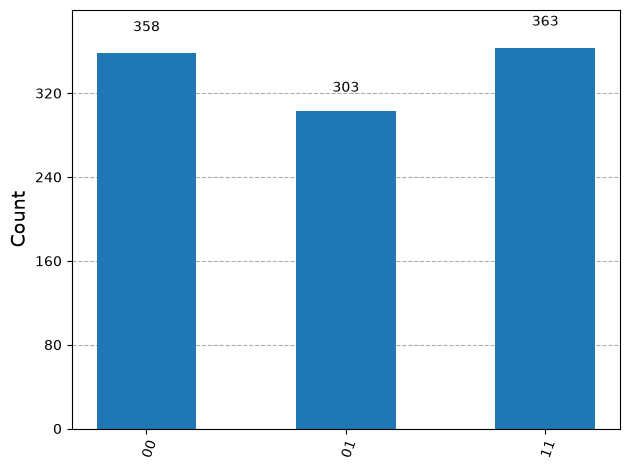

In [3]:
q = QuantumRegister(2, 'q')  #00, 01, 11
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

theta = 2 * np.arccos(1 / np.sqrt(3))

qc.ry(theta, q[0])
qc.ch(q[0], q[1])

qc.measure(q[0:2], c[0:2])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

{'01': 356, '11': 340, '10': 328}


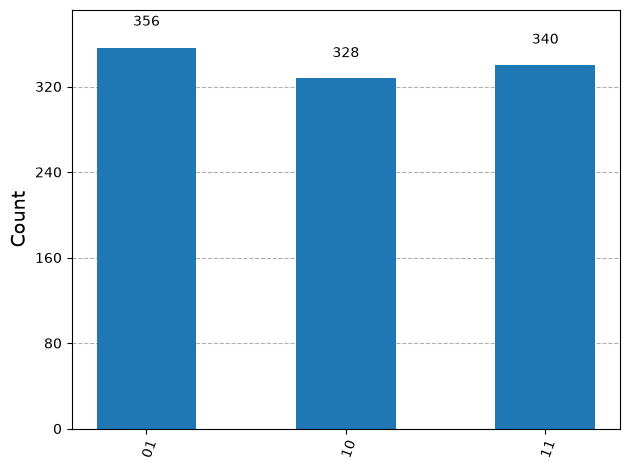

In [4]:
q = QuantumRegister(2, 'q')  #01, 10, 11
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

theta = 2 * np.arccos(1 / np.sqrt(3))

qc.ry(theta, q[0])
qc.ch(q[0], q[1])
qc.x(q[1])

qc.measure(q[0:2], c[0:2])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

{'00': 324, '10': 341, '11': 359}


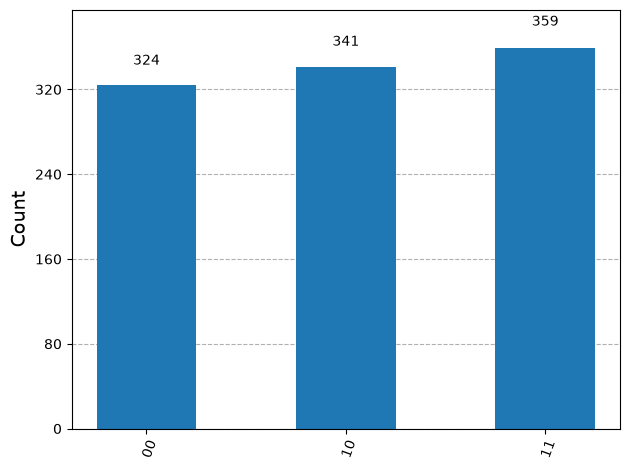

In [5]:
q = QuantumRegister(2, 'q')  #00, 10, 11
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

theta = 2 * np.arccos(1 / np.sqrt(3))

qc.ry(theta, q[1])
qc.ch(q[1], q[0])
qc.measure(q[0:2], c[0:2])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)

{'10': 348, '00': 332, '01': 344}


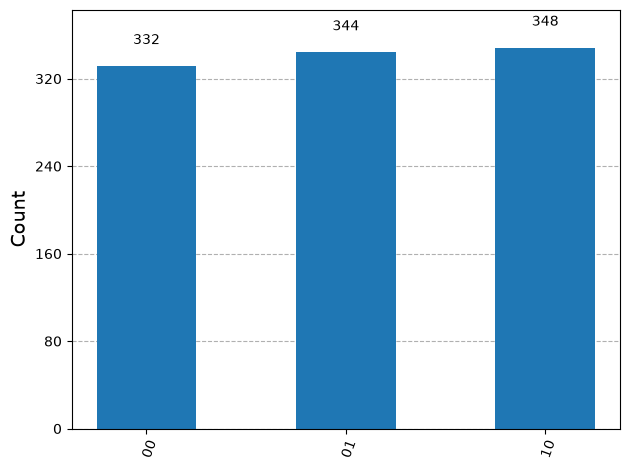

In [6]:
q = QuantumRegister(2, 'q')  #00, 01, 10
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

theta = 2 * np.arccos(1 / np.sqrt(3))

qc.ry(theta, q[1])
qc.ch(q[1], q[0])
qc.x(q[1])

qc.measure(q[0:2], c[0:2])

r = execute(qc, Aer.get_backend('qasm_simulator')).result()
rc = r.get_counts()
print(rc)
plot_histogram(rc)